## IMPORTS


In [15]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats.mstats import winsorize

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

ROOT = Path(".") if Path("data").exists() else Path("..")
FIRE_PATH = ROOT / "data/raw/fires/firms_noaa20_2025_mar_nov.csv"
OUT_DIR = ROOT / "data/processed"
OUT_DIR.mkdir(parents=True, exist_ok=True)

DELHI_LAT, DELHI_LON = 28.53, 77.19
START, END = "2025-03-01", "2025-11-30"

# LOAD


In [16]:
fires_raw = pd.read_csv(FIRE_PATH)
fires_raw.shape

(26564, 15)

In [17]:
fires_raw.head(10)

,latitude,longitude,bright_ti4,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_ti5,frp,daynight,type
0,27.80350,74.29232,346.62,0.41,0.37,2025-03-01,800,N20,VIIRS,n,2,305.43,2.36,D,0
1,27.83237,76.25237,335.15,0.38,0.36,2025-03-01,800,N20,VIIRS,n,2,302.59,2.21,D,0
2,27.83296,76.25623,333.15,0.38,0.36,2025-03-01,800,N20,VIIRS,n,2,302.97,2.21,D,0
3,28.35821,78.28951,337.20,0.41,0.37,2025-03-01,800,N20,VIIRS,n,2,287.18,3.97,D,0
4,28.63930,77.84122,342.46,0.40,0.37,2025-03-01,800,N20,VIIRS,n,2,298.73,7.68,D,0
5,28.78403,78.51958,328.41,0.42,0.38,2025-03-01,800,N20,VIIRS,n,2,297.36,2.47,D,0
6,29.56946,74.33430,333.82,0.40,0.37,2025-03-01,800,N20,VIIRS,n,2,298.29,4.25,D,0
7,29.57011,74.33835,335.47,0.40,0.37,2025-03-01,800,N20,VIIRS,n,2,295.39,4.07,D,0
8,30.18062,74.42857,349.07,0.39,0.36,2025-03-01,800,N20,VIIRS,n,2,296.60,3.91,D,0
9,30.18394,74.42786,348.75,0.39,0.36,2025-03-01,800,N20,VIIRS,n,2,297.41,4.04,D,0


In [18]:
fires_raw.tail(5)

,latitude,longitude,bright_ti4,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_ti5,frp,daynight,type
26559,30.70905,78.13254,296.87,0.59,0.70,2025-11-30,2129,N20,VIIRS,n,2,280.90,0.56,N,0
26560,27.37245,77.69308,367.00,0.67,0.74,2025-11-30,2130,N20,VIIRS,h,2,285.72,14.43,N,0
26561,27.37420,77.68658,296.08,0.67,0.74,2025-11-30,2130,N20,VIIRS,n,2,285.62,8.12,N,0
26562,27.37672,77.69276,352.30,0.67,0.74,2025-11-30,2130,N20,VIIRS,n,2,285.80,10.01,N,0
26563,28.73149,76.52918,308.18,0.53,0.67,2025-11-30,2130,N20,VIIRS,n,2,278.84,1.98,N,0


In [19]:
fires_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 26564 entries, 0 to 26563
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   latitude    26564 non-null  float64
 1   longitude   26564 non-null  float64
 2   bright_ti4  26564 non-null  float64
 3   scan        26564 non-null  float64
 4   track       26564 non-null  float64
 5   acq_date    26564 non-null  str    
 6   acq_time    26564 non-null  int64  
 7   satellite   26564 non-null  str    
 8   instrument  26564 non-null  str    
 9   confidence  26564 non-null  str    
 10  version     26564 non-null  int64  
 11  bright_ti5  26564 non-null  float64
 12  frp         26564 non-null  float64
 13  daynight    26564 non-null  str    
 14  type        26564 non-null  int64  
dtypes: float64(7), int64(3), str(5)
memory usage: 3.5 MB


In [20]:
fires_raw.describe()

,latitude,longitude,bright_ti4,scan,track,acq_time,version,bright_ti5,frp,type
count,26564.000000,26564.000000,26564.000000,26564.000000,26564.000000,26564.000000,26564.0,26564.000000,26564.000000,26564.000000
mean,29.876688,76.035252,336.818224,0.456774,0.489055,915.924258,2.0,303.210724,5.827899,0.026766
std,0.850504,1.249713,13.042879,0.084495,0.111178,397.602672,0.0,7.975684,6.926659,0.230555
min,27.000580,74.000000,295.000000,0.320000,0.360000,651.000000,2.0,252.410000,0.080000,0.000000
25%,29.406962,75.025958,332.880000,0.390000,0.390000,730.000000,2.0,299.290000,2.497500,0.000000
50%,30.067505,75.985635,337.910000,0.440000,0.460000,806.000000,2.0,303.360000,4.170000,0.000000
75%,30.560842,76.836535,343.530000,0.500000,0.580000,832.000000,2.0,307.662500,6.880000,0.000000
max,31.000000,78.999870,367.000000,0.800000,0.780000,2148.000000,2.0,360.290000,198.550000,3.000000


In [21]:
print("Duplicate rows:", fires_raw.duplicated().sum())
print("Missing cells:", fires_raw.isna().sum().sum())
fires_raw.nunique()

Duplicate rows: 0
Missing cells: 0


latitude      25085
longitude     25583
bright_ti4     4408
scan             49
track            43
acq_date        242
acq_time        194
satellite         1
instrument        1
confidence        3
version           1
bright_ti5     4042
frp            2277
daynight          2
type              3
dtype: int64

### Categorical columns and date range

In [22]:
for col in ["confidence", "daynight", "type"]:
    print(col, fires_raw[col].value_counts().to_dict())

fires_raw["acq_date"].agg(["min", "max"])

confidence {'n': 20787, 'l': 4949, 'h': 828}
daynight {'D': 23624, 'N': 2940}
type {0: 26210, 2: 351, 3: 3}


min    2025-03-01
max    2025-11-30
Name: acq_date, dtype: str

In [23]:
fires = fires_raw.copy()

constant_cols = [c for c in fires.columns if fires[c].nunique() == 1]
fires = fires.drop(columns=constant_cols)
constant_cols

['satellite', 'instrument', 'version']

they have only one value throughout the dataset , so remove it

In [24]:
fires["type"].value_counts()

type
0    26210
2      351
3        3
Name: count, dtype: int64

In [25]:
fires = fires[fires["type"] == 0].drop(columns="type").reset_index(drop=True)
len(fires)

26210

utc to ist


In [26]:
hhmm = fires["acq_time"].astype(str).str.zfill(4)
fires["time_utc"] = pd.to_datetime(fires["acq_date"] + " " + hhmm, format="%Y-%m-%d %H%M")
fires["time_ist"] = fires["time_utc"] + pd.Timedelta(hours=5, minutes=30)
fires["date"] = fires["time_ist"].dt.normalize()
fires["hour_ist"] = fires["time_ist"].dt.hour
fires["month"] = fires["date"].dt.month

In [27]:
date_shifted = fires["date"] != pd.to_datetime(fires["acq_date"])
pd.crosstab(fires["daynight"], date_shifted, colnames=["IST date differs"])

IST date differs,False,True
daynight,,
D,23619,0
N,0,2591


In [28]:
fires.groupby("daynight")["hour_ist"].agg(["min", "median", "max"])

,min,median,max
daynight,,,
D,12,13.0,14
N,0,2.0,3


In [29]:
in_period = fires["date"].between(START, END)
fires = fires[in_period].reset_index(drop=True)
(~in_period).sum()

np.int64(45)

In [30]:
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

fires["dist_km"] = haversine_km(fires["latitude"], fires["longitude"], DELHI_LAT, DELHI_LON)

In [31]:
fires["in_delhi"] = fires["latitude"].between(28.40, 28.88) & fires["longitude"].between(76.84, 77.35)
fires["dist_km"].describe().round(1)

count    26165.0
mean       223.5
std         95.7
min          4.5
25%        153.1
50%        235.1
75%        297.6
max        410.4
Name: dist_km, dtype: float64

In [32]:
fires["in_delhi"].sum()

np.int64(461)

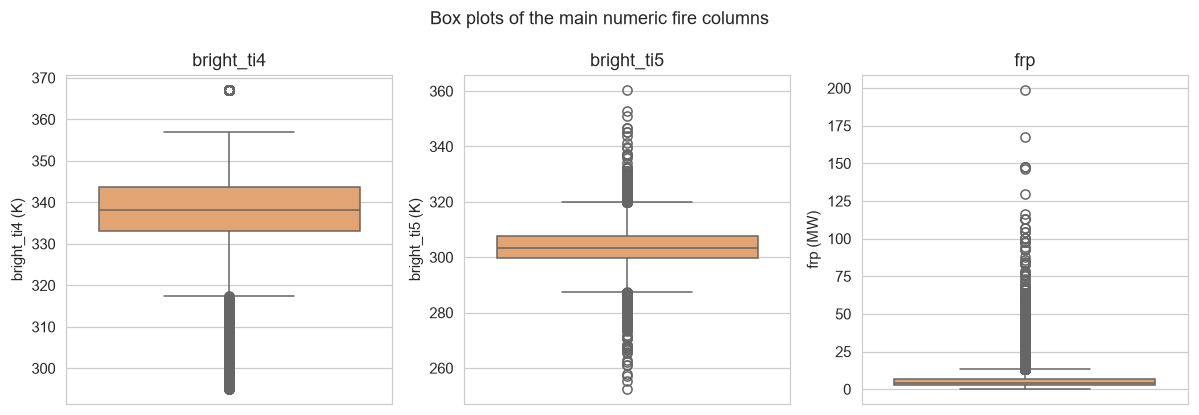

In [33]:
units = {"bright_ti4": "K", "bright_ti5": "K", "frp": "MW"}

fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
for ax, col in zip(axes, units):
    sns.boxplot(y=fires[col], ax=ax, color="#f4a261")
    ax.set_title(col)
    ax.set_ylabel(f"{col} ({units[col]})")
fig.suptitle("Box plots of the main numeric fire columns")
fig.tight_layout()
plt.show()